# Multimodal Movie Recap — AI11 Module 08 Assignment
**Pipeline:** YouTube Video → Audio + Video → Transcript → Summary Story → Peak Points → Time Index → OpenCV Segment Extraction → Movie Recap (< 10 min) → BLEU

### One-time setup (already done? just use **Runtime → Run all**)
1. **Runtime → Change runtime type → T4 GPU**.
2. In Google Drive, create a folder **`movie-recap-work`** in My Drive and upload **`movie-recap.zip`** into it.
3. The film (`film.mp4`) can be in **My Drive** or in **`movie-recap-work`**.
4. Colab **Secrets** (🔑 on the left): `GEMINI_API_KEY` with **Notebook access ON**.
5. Paste the reference summary into the cell in section 4 (once), then **File → Save**.

All results are written to **`My Drive/movie-recap-work/outputs`**, so they survive Colab resets and re-runs skip finished steps.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Connect Google Drive

In [3]:
import os, subprocess
from google.colab import drive
drive.mount('/content/drive')

WORK = '/content/drive/MyDrive/movie-recap-work'
OUT = f'{WORK}/outputs'
os.makedirs(OUT, exist_ok=True)
print('Work folder:', WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Work folder: /content/drive/MyDrive/movie-recap-work


## 2. Get the project code and install libraries

In [4]:
ZIP = f'{WORK}/movie-recap.zip'
assert os.path.exists(ZIP), f'Upload movie-recap.zip into My Drive/movie-recap-work first ({ZIP} not found)'
%cd /content
!rm -rf /content/movie-recap
!unzip -q -o "{ZIP}" -d /content
%cd /content/movie-recap
!ls

/content
/content/movie-recap
config.py  main.py		    outputs    requirements.txt  tests
data	   Movie_Recap_Colab.ipynb  README.md  src


In [5]:
!apt-get -qq install -y ffmpeg > /dev/null
!pip -q install -r requirements.txt
print('Libraries installed')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.7/183.7 kB 14.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 83.9 MB/s eta 0:00:00
Libraries installed


## 3. Settings and input video

In [6]:
from google.colab import userdata

try:
    os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')
except Exception as e:
    raise SystemExit('GEMINI_API_KEY not available. Add it in Secrets (key icon) and turn ON Notebook access, then Run all again.')
#os.environ['SUMMARIZER'] = 'bart'
os.environ['SUMMARIZER'] = 'gemini'
os.environ['GEMINI_MODEL'] = 'gemini-3.8-flash'
os.environ['WHISPER_MODEL'] = 'small'

YOUTUBE_URL = 'https://www.youtube.com/watch?v=H91BxkBXttE'   # Night of the Living Dead (1968), public domain
print('Summarizer:', os.environ['SUMMARIZER'], '/', os.environ['GEMINI_MODEL'])

Summarizer: gemini / gemini-3.8-flash


In [7]:
# The film is downloaded once on a laptop with yt-dlp (YouTube blocks downloads from Colab)
# and stored in Drive. YouTube serves AV1 video, which OpenCV cannot decode, so it is
# converted once to H.264. The conversion writes to a temporary name and is renamed only
# when complete, so a half-finished file is never used.

def duration(path):
    r = subprocess.run(['ffprobe', '-v', 'error', '-show_entries', 'format=duration',
                        '-of', 'default=nw=1:nk=1', path], capture_output=True, text=True)
    try:
        return float(r.stdout.strip())
    except ValueError:
        return 0.0

candidates = [f'{WORK}/film.mp4', '/content/drive/MyDrive/film.mp4']
SOURCE = next((c for c in candidates if os.path.exists(c)), None)
assert SOURCE, f'film.mp4 not found. Put it in {WORK} or My Drive.'
src_dur = duration(SOURCE)
print(f'Source film: {SOURCE}  ({src_dur/60:.1f} min)')

VIDEO = f'{WORK}/film_h264.mp4'
if os.path.exists(VIDEO) and abs(duration(VIDEO) - src_dur) > 5:
    print('Existing H.264 copy is incomplete - redoing conversion')
    os.remove(VIDEO)
if not os.path.exists(VIDEO):
    print('Converting to H.264 (one-time, ~15-25 min)...')
    tmp = '/content/film_h264_tmp.mp4'
    !ffmpeg -y -loglevel error -i "{SOURCE}" -c:v libx264 -preset veryfast -crf 23 -c:a aac -b:a 128k "{tmp}"
    assert abs(duration(tmp) - src_dur) <= 5, 'Conversion failed or incomplete'
    !cp "{tmp}" "{VIDEO}"
print(f'Input video for pipeline: {VIDEO}  ({duration(VIDEO)/60:.1f} min)')

Source film: /content/drive/MyDrive/film.mp4  (95.3 min)
Input video for pipeline: /content/drive/MyDrive/movie-recap-work/film_h264.mp4  (95.3 min)


## 4. Reference summary (for BLEU / ROUGE)
Source: the **Plot** section of the film's Wikipedia page — https://en.wikipedia.org/wiki/Night_of_the_Living_Dead
Paste it between the triple quotes **once** and save the notebook. It is also stored in Drive, so later runs reuse it.

In [8]:
REFERENCE_TEXT = """
Siblings Barbra and Johnny Blair drive to a cemetery in rural Pennsylvania to visit their father's grave, where a pale man in a tattered suit kills Johnny and attacks Barbra. Fleeing to a nearby farmhouse, she finds the resident's corpse lying half-eaten on the stairs. A growing horde of ghouls surrounds the house as a stranger, Ben, arrives and initially mistakes Barbra for the homeowner. After driving back several ghouls, he boards the windows and doors. A traumatized Barbra falls into a near catatonic state, forcing Ben to look after her. While searching the home for supplies, he locates a lever-action rifle upstairs.
Barbra is surprised to find people already taking shelter in the home's cellar. Harry Cooper, his wife Helen, and their young daughter Karen fled there after ghouls overturned their car and bit Karen on the arm, leaving her seriously ill. A teenage couple, Tom and Judy, took shelter after hearing an emergency broadcast while they were at a nearby lake. Tom and Ben secure the farmhouse while Harry protests that it is unsafe aboveground, before returning to the cellar. Tension rises in the group as more of the ghouls arrive to besiege the farmhouse.
Through radio and TV reports, the survivors learn that cannibalistic corpses, referred to as "ghouls", are reanimating and committing mass murder across the East Coast of the United States and that posses of armed men are patrolling the countryside to exterminate the living dead. Reports confirm that the ghouls can die again from heavy blows to the head, bullets to the brain, or being burned. Various rescue centers offer refuge and safety, and scientists theorize that radiation from an exploding space probe returning from Venus caused the reanimations.
Ben devises a plan to obtain medical supplies for Karen and transport the group to a rescue center by refueling his truck at a pump on the farm. Ben, Tom, and Judy drive there together, holding the ghouls off with torches and Molotov cocktails. However, spilled gasoline catches fire and causes the truck to explode, killing Tom and Judy. Ben makes it back, but when Harry refuses to unlock the door, Ben breaks it down.
The remaining survivors debate possible options, pausing when the 3 a.m. news broadcast airs. As they watch the update, the power fails, and the ghouls break through the doors and windows of the unlit home. In the chaos, Harry grabs Ben's gun to threaten him, but is disarmed and shot by Ben. Harry staggers down to the cellar and dies beside his daughter. Barbra awakens from her delirium and saves Helen from the ghouls, who then flees to the cellar.
Karen dies from her injuries, becomes a ghoul, feeds on her father's remains, and stabs her mother to death with a masonry trowel. Barbra tries to help Ben keep the ghouls out, but freezes upon seeing the reanimated Johnny, who drags her into the horde. As the horde pours into the farmhouse, Ben retreats to the cellar, where he shoots the reanimated Harry and Helen.
In the morning, an armed posse arrives to dispatch the remaining ghouls. Awakened by their gunfire, Ben emerges from the cellar, but, mistaking him for a ghoul, the posse shoots him. His body is thrown onto a bonfire and burned with the other corpses.
"""

REF_FILE = f'{WORK}/reference_summary.txt'
if 'PASTE THE WIKIPEDIA PLOT' not in REFERENCE_TEXT:
    open(REF_FILE, 'w', encoding='utf-8').write(REFERENCE_TEXT.strip())
assert os.path.exists(REF_FILE), 'Paste the reference summary into REFERENCE_TEXT above, then run again.'
ref = open(REF_FILE, encoding='utf-8').read()
print(f'Reference summary: {len(ref.split())} words')
print(ref[:300], '...')

Reference summary: 549 words
Siblings Barbra and Johnny Blair drive to a cemetery in rural Pennsylvania to visit their father's grave, where a pale man in a tattered suit kills Johnny and attacks Barbra. Fleeing to a nearby farmhouse, she finds the resident's corpse lying half-eaten on the stairs. A growing horde of ghouls surr ...


## 5. Test each component (guideline 15)

In [9]:
!python -m pytest -q tests

..........                                                               [100%]
10 passed in 34.64s


## 6. Run the full pipeline
First run: ~15 min Whisper + 1 Gemini call + ~5-10 min clip extraction. Later runs reuse the cached transcript and summary from Drive.

In [10]:
!python main.py --source "{VIDEO}" --reference "{REF_FILE}" --out "{OUT}"

[1] Video: 640x480 @ 30.0 fps, 95.3 min
[2] Audio extracted -> data/audio.wav
[3] Loaded cached transcript (496 segments, up to 93.1 min)
[summarize] API busy/rate-limited, retrying in 20s
[summarize] 1 chunks -> story of 299 words
modules.json: 100% 349/349 [00:00<00:00, 1.98MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 688kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 13.5MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 325kB/s]
config.json: 100% 612/612 [00:00<00:00, 3.31MB/s]

model.safetensors: downloading bytes:  94% 85.0M/90.9M [00:01<00:00, 83.1MB/s, 6.68MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 47.9MB/s, 8.00MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 51.2MB/s, 8.68MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 7140.60it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 2.23MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 62.3MB/s]
tokenizer.json: 100% 466k/466k [00:0

## 7. Results

### Summary story

In [11]:
print(open(f'{OUT}/summary_story.txt').read())

Siblings Barbra and Johnny visit their father’s grave in a rural Pennsylvania cemetery, where Johnny is abruptly attacked and killed by an aggressive stranger. Barbra flees in terror to an isolated farmhouse and is soon joined by a resourceful stranger named Ben, who works urgently to board up the windows against a gathering swarm of reanimated corpses. They soon discover five other survivors hiding in the cellar: the argumentative Harry Cooper, his wife Helen, their feverish daughter Karen, and a young couple named Tom and Judy. A bitter power struggle immediately erupts between Ben, who insists on defending the main floor to maintain an escape route, and Harry, who demands everyone seal themselves in the cellar. Broadcast news bulletins eventually clarify the nightmare, reporting that recently deceased bodies are reanimating across the nation to consume human flesh due to mysterious space radiation. Hoping to reach a nearby rescue center, Ben, Tom, and Judy coordinate a desperate att

### Summary sentence → time index, and peak points used in the recap

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', 120)
print('Summary sentence -> time index')
display(pd.read_csv(f'{OUT}/summary_to_timestamps.csv'))
print('Peak points (recap order)')
display(pd.read_csv(f'{OUT}/peak_points.csv').drop(columns=['clip_file']))

### Multimodal importance over the film

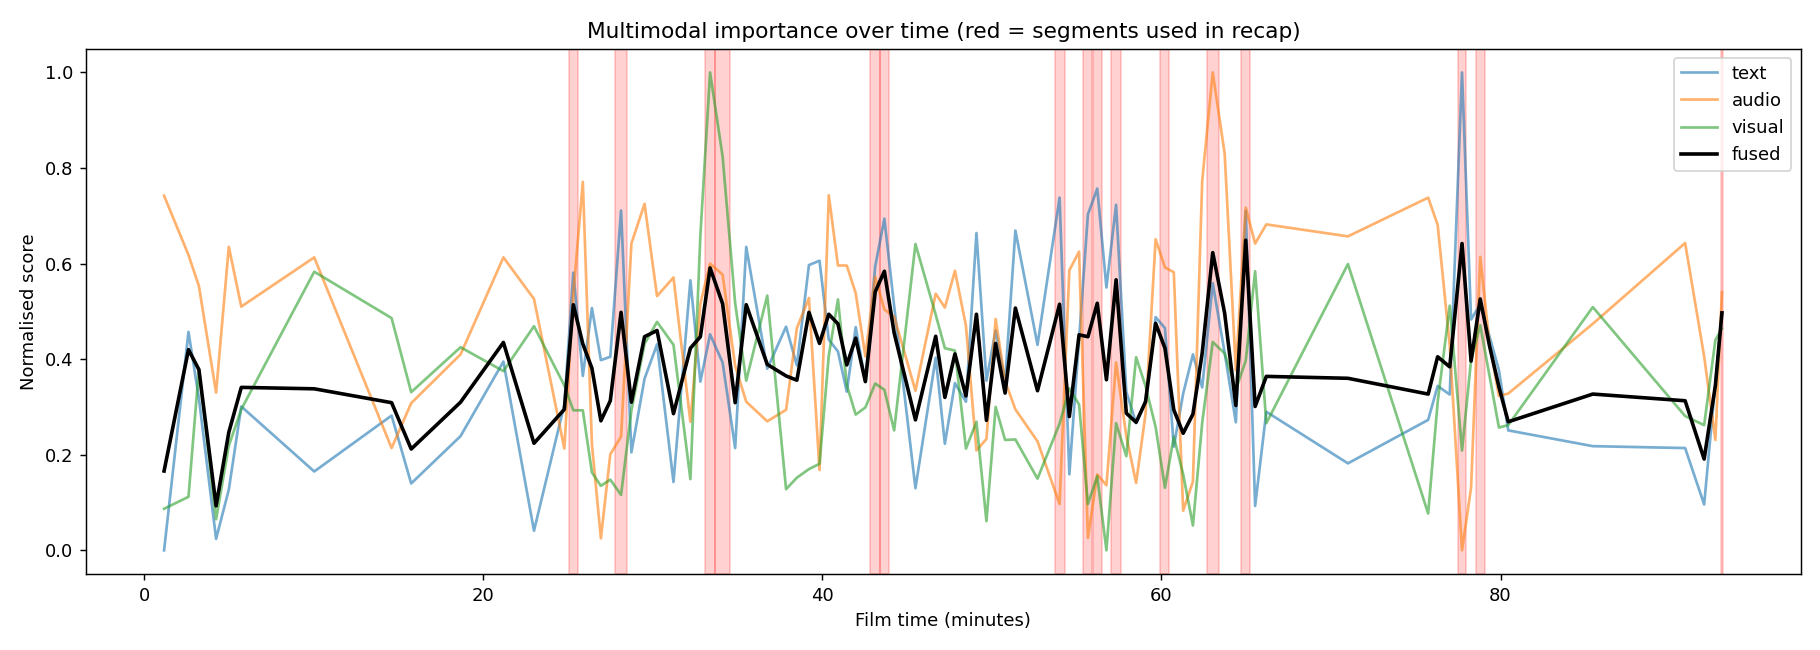

In [12]:
from IPython.display import Image
Image(f'{OUT}/importance_timeline.png')

### Evaluation

In [13]:
import json
print(json.dumps(json.load(open(f'{OUT}/evaluation.json')), indent=2))

{
  "bleu": {
    "BLEU-1": 0.2646,
    "BLEU-2": 0.1566,
    "BLEU-3": 0.0878,
    "BLEU-4": 0.0553
  },
  "rouge": {
    "rouge1": 0.4354,
    "rouge2": 0.126,
    "rougeL": 0.2608
  },
  "candidate_words": 299,
  "reference_words": 549
}


### Recap video

In [14]:
recap = f'{OUT}/movie_recap.mp4'
print(f'Recap duration: {duration(recap)/60:.2f} min  (limit: 10 min)')
print('Size:', round(os.path.getsize(recap)/1e6, 1), 'MB  ->  also saved in My Drive/movie-recap-work/outputs/')

Recap duration: 9.39 min  (limit: 10 min)
Size: 32.5 MB  ->  also saved in My Drive/movie-recap-work/outputs/


In [ ]:
# Inline preview (skipped for very large files - open it from Drive instead)
from IPython.display import HTML
from base64 import b64encode
if os.path.getsize(recap) < 80e6:
    data = b64encode(open(recap, 'rb').read()).decode()
    display(HTML(f'<video width=640 controls src="data:video/mp4;base64,{data}"></video>'))
else:
    print('Recap is large - open it from Google Drive.')

## 8. Package results for submission

In [16]:
!cd "{WORK}" && zip -qr /content/outputs.zip outputs -x 'outputs/clips/*' 'outputs/movie_recap.mp4'
from google.colab import files
files.download('/content/outputs.zip')
print('Downloaded outputs.zip (tables, plots, report). The recap video stays in Drive.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded outputs.zip (tables, plots, report). The recap video stays in Drive.
